In [ ]:
%pip install -q kagglehub numpy pandas matplotlib pillow scipy scikit-learn

import kagglehub

dataset_path = kagglehub.dataset_download(
    "murtozalikhon/brain-tumor-multimodal-image-ct-and-mri"
)
print(dataset_path)

In [7]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import os
import platform
import random
import sys
import time
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.fft import dctn
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, roc_curve, precision_recall_curve, average_precision_score,
    balanced_accuracy_score, brier_score_loss
)
from sklearn.calibration import calibration_curve
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.transforms import InterpolationMode
from IPython.display import display

## Settings

In [8]:
MODE = 'full'
SEED = 42
DATA_ROOT = dataset_path
DATA_ZIP = None
PATIENT_MAPPING = None
OUTPUT_ROOT = Path('results')
PRETRAINED = True
IMAGE_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 20
PATIENCE = 4
LEARNING_RATE = 1e-4
FOLDS = 5
RUN_CV = False
TARGET_RECALL = 0.95
BOOTSTRAPS = 300
PHASH_DISTANCE = 3
CROP_FOREGROUND = True
SMOKE_PER_STRATUM = 4
CV_NAMES = None

if MODE == 'smoke':
    PRETRAINED = False
    IMAGE_SIZE = 64
    BATCH_SIZE = 8
    EPOCHS = 1
    PATIENCE = 1
    BOOTSTRAPS = 30

assert MODE in {'full', 'smoke'}
assert FOLDS == 5
assert 0 <= PHASH_DISTANCE <= 3
OUT = OUTPUT_ROOT / MODE
for folder in ['audit', 'figures', 'models', 'tables', 'predictions', 'cv']:
    (OUT / folder).mkdir(parents=True, exist_ok=True)
torch.hub.set_dir(str(OUT / 'weight_cache'))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, os.cpu_count() or 1))

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)

set_seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

def save_figure(name):
    plt.gcf().suptitle(f'{MODE.upper()} | ' + name.replace('_', ' '), fontsize=12)
    plt.tight_layout()
    plt.savefig(OUT / 'figures' / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()

settings = {key: globals()[key] for key in [
    'MODE', 'SEED', 'PRETRAINED', 'IMAGE_SIZE', 'BATCH_SIZE', 'EPOCHS', 'PATIENCE',
    'LEARNING_RATE', 'FOLDS', 'RUN_CV', 'TARGET_RECALL', 'PHASH_DISTANCE',
    'CROP_FOREGROUND', 'BOOTSTRAPS', 'SMOKE_PER_STRATUM', 'CV_NAMES'
]}
settings['device'] = str(DEVICE)
settings['versions'] = {p: importlib.metadata.version(p) for p in [
    'torch', 'torchvision', 'numpy', 'pandas', 'matplotlib', 'pillow', 'scikit-learn'
]}
settings['python'] = platform.python_version()
(OUT / 'settings.json').write_text(json.dumps(settings, indent=2))
display(pd.DataFrame({'setting': ['mode', 'device', 'image size', 'epochs', 'folds'],
                      'value': [MODE, str(DEVICE), IMAGE_SIZE, EPOCHS, FOLDS]}))

,setting,value
0,mode,full
1,device,cpu
2,image size,224
3,epochs,20
4,folds,5


## Locate and audit every image



In [9]:
def locate_data():
    if DATA_ROOT is not None:
        root = Path(DATA_ROOT).expanduser().resolve()
        if not root.is_dir():
            raise FileNotFoundError(root)
        return root
    candidates = [Path('archive (1)/Dataset'), Path('Dataset'), Path('dataset')]
    for candidate in candidates:
        if candidate.is_dir():
            return candidate.resolve()
    archives = [Path(DATA_ZIP)] if DATA_ZIP else sorted(Path('.').glob('*.zip'))
    if len(archives) != 1:
        raise FileNotFoundError('Set DATA_ROOT or DATA_ZIP to your dataset.')
    target = Path('extracted_dataset').resolve()
    with zipfile.ZipFile(archives[0]) as archive:
        for item in archive.infolist():
            destination = (target / item.filename).resolve()
            if not destination.is_relative_to(target):
                raise ValueError('Unsafe archive path')
        archive.extractall(target)
    return target

ROOT = locate_data()
rows, rejected = [], []
extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
for path in sorted(ROOT.rglob('*')):
    if path.suffix.lower() not in extensions or not path.is_file():
        continue
    relative = path.relative_to(ROOT).as_posix()
    parents = [p.lower() for p in path.relative_to(ROOT).parts[:-1]]
    modality = 'MRI' if any('mri' in p for p in parents) else (
        'CT' if any('ct' in p for p in parents) else None)
    label = 0 if path.parent.name.lower() == 'healthy' else (
        1 if path.parent.name.lower() in {'tumor', 'tumour'} else None)
    if modality is None or label is None:
        rejected.append({'path': relative, 'reason': 'Unknown folder label'})
        continue
    try:
        with Image.open(path) as source:
            gray = ImageOps.exif_transpose(source).convert('L')
            gray.load()
            pixels = np.asarray(gray)
            small = np.asarray(gray.resize((32, 32), Image.Resampling.LANCZOS), dtype=float)
            low = dctn(small, norm='ortho')[:8, :8].ravel()
            bits = low > np.median(low[1:])
            bits[0] = False
            phash = int(''.join('1' if b else '0' for b in bits), 2)
            rows.append({'path': relative, 'modality': modality, 'label': label,
                         'class': ['Healthy', 'Tumour'][label], 'width': gray.width,
                         'height': gray.height, 'mean_intensity': float(pixels.mean()),
                         'file_hash': hashlib.sha256(path.read_bytes()).hexdigest(),
                         'pixel_hash': hashlib.sha256(str(gray.size).encode() + pixels.tobytes()).hexdigest(),
                         'phash': f'{phash:016x}'})
    except (OSError, ValueError) as error:
        rejected.append({'path': relative, 'reason': str(error)})

raw = pd.DataFrame(rows)
if raw.empty or set(raw.modality) != {'CT', 'MRI'} or raw.label.nunique() != 2:
    raise ValueError('Expected healthy and tumour images for CT and MRI.')
pd.DataFrame(rejected, columns=['path', 'reason']).to_csv(OUT / 'audit/rejected.csv', index=False)
for path in ROOT.rglob('*.txt'):
    name = path.parent.name.replace(' ', '_') + '_' + path.name.replace(' ', '_')
    (OUT / 'audit' / name).write_bytes(path.read_bytes())

parents = list(range(len(raw)))

def find(i):
    while parents[i] != i:
        parents[i] = parents[parents[i]]
        i = parents[i]
    return i

def union(i, j):
    a, b = find(i), find(j)
    if a != b:
        parents[b] = a

for column in ['file_hash', 'pixel_hash']:
    for indices in raw.groupby(column).groups.values():
        indices = list(indices)
        for index in indices[1:]:
            union(indices[0], index)

bands = {}
similar_pairs = []
hash_values = [int(value, 16) for value in raw.phash]
for i, value in enumerate(raw.phash):
    value = int(value, 16)
    candidates = set()
    keys = [(band, (value >> (16 * band)) & 65535) for band in range(4)]
    for key in keys:
        candidates.update(bands.get(key, []))
    for j in candidates:
        if (value ^ hash_values[j]).bit_count() <= PHASH_DISTANCE:
            union(i, j)
            if len(similar_pairs) < 200:
                similar_pairs.append((i, j))
    for key in keys:
        bands.setdefault(key, []).append(i)

raw['similarity_group'] = [f's{find(i)}' for i in range(len(raw))]
if PATIENT_MAPPING:
    mapping = pd.read_csv(PATIENT_MAPPING, dtype=str)
    if not {'path', 'patient_id'}.issubset(mapping.columns):
        raise ValueError('Patient mapping needs path and patient_id.')
    mapping['path'] = mapping.path.str.replace('\\', '/', regex=False)
    if mapping.path.duplicated().any() or mapping.patient_id.isna().any():
        raise ValueError('Patient mapping has duplicates or missing IDs.')
    merged = raw[['path']].merge(mapping, on='path', how='left', validate='one_to_one')
    if merged.patient_id.isna().any():
        raise ValueError('Patient mapping must cover every image.')
    for indices in merged.groupby('patient_id').groups.values():
        indices = list(indices)
        for index in indices[1:]:
            union(indices[0], index)

raw['group'] = [f'g{find(i)}' for i in range(len(raw))]
conflicts = raw.groupby('similarity_group').agg(labels=('label', 'nunique'), modalities=('modality', 'nunique'))
bad_groups = conflicts.index[(conflicts.labels > 1) | (conflicts.modalities > 1)]
quarantined = raw[raw.similarity_group.isin(bad_groups)]
eligible = raw[~raw.similarity_group.isin(bad_groups)].copy()
duplicates = eligible[eligible.duplicated('pixel_hash', keep='first')]
clean = eligible.drop_duplicates('pixel_hash').copy().reset_index(drop=True)
clean['stratum'] = clean.modality + '_' + clean.label.astype(str)
raw.to_csv(OUT / 'audit/raw_manifest.csv', index=False)
quarantined.to_csv(OUT / 'audit/quarantined.csv', index=False)
duplicates.to_csv(OUT / 'audit/exact_duplicates.csv', index=False)
clean.to_csv(OUT / 'audit/clean_manifest.csv', index=False)
audit_summary = pd.DataFrame({'stage': ['Decoded', 'Rejected', 'Quarantined', 'Duplicates removed', 'Retained'],
                              'images': [len(raw), len(rejected), len(quarantined), len(duplicates), len(clean)]})
audit_summary.to_csv(OUT / 'tables/audit_summary.csv', index=False)
display(audit_summary)

,stage,images
0,Decoded,9618
1,Rejected,0
2,Quarantined,172
3,Duplicates removed,539
4,Retained,8907


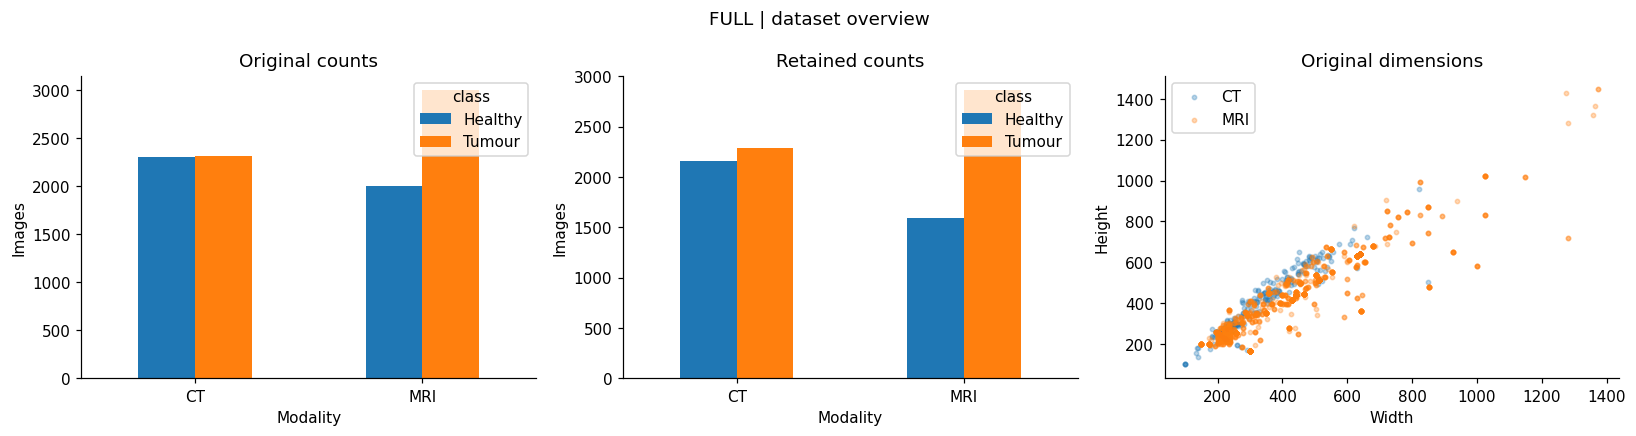

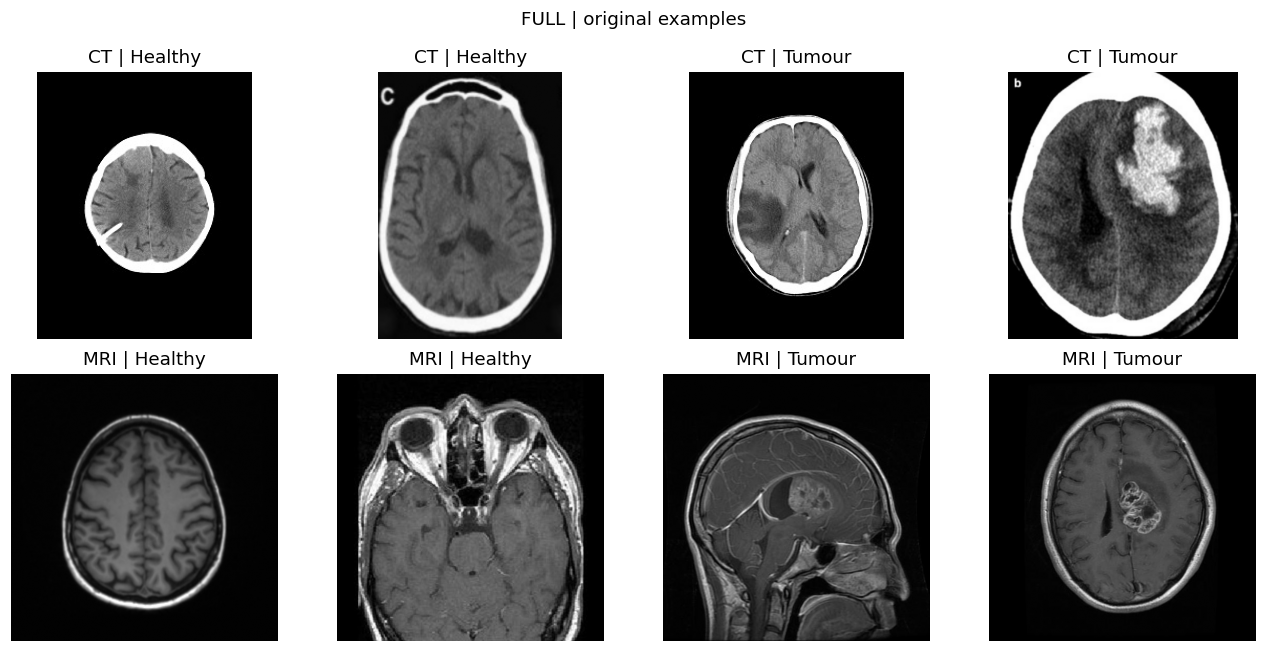

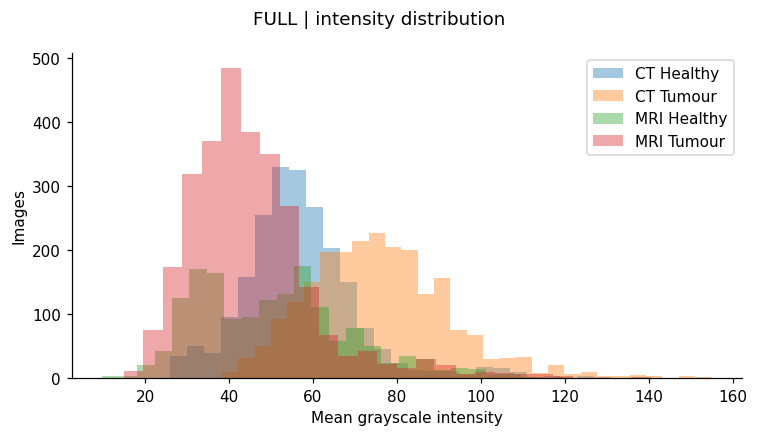

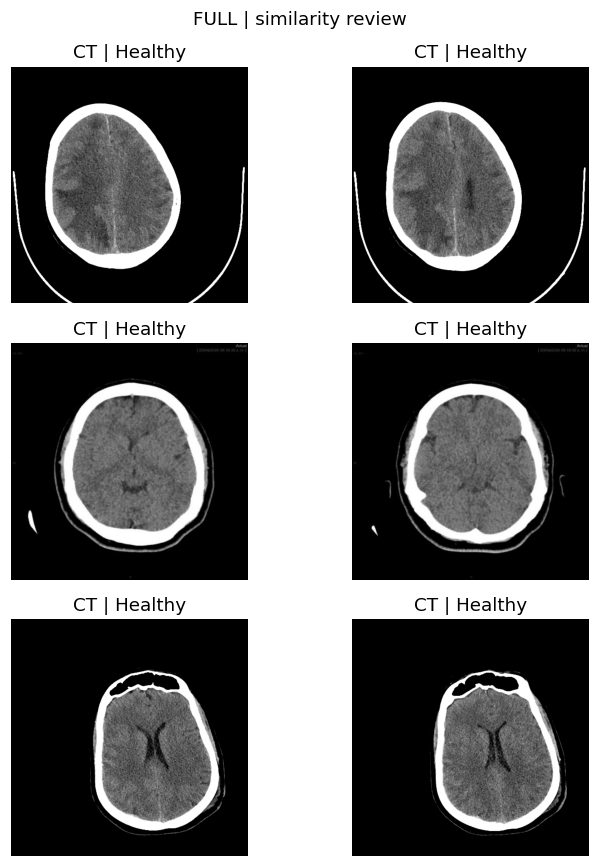

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for frame, title, ax in [(raw, 'Original counts', axes[0]), (clean, 'Retained counts', axes[1])]:
    frame.groupby(['modality', 'class']).size().unstack().plot.bar(ax=ax, rot=0)
    ax.set(title=title, ylabel='Images', xlabel='Modality')
for modality, group in raw.groupby('modality'):
    axes[2].scatter(group.width, group.height, s=8, alpha=.3, label=modality)
axes[2].set(xlabel='Width', ylabel='Height', title='Original dimensions')
axes[2].legend()
save_figure('dataset_overview')

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for row, modality in enumerate(['CT', 'MRI']):
    for col, label in enumerate([0, 0, 1, 1]):
        sample = clean[(clean.modality == modality) & (clean.label == label)].iloc[col % 2]
        with Image.open(ROOT / sample.path) as im:
            axes[row, col].imshow(im.convert('L'), cmap='gray')
        axes[row, col].set_title(f'{modality} | {sample["class"]}')
        axes[row, col].axis('off')
save_figure('original_examples')

fig, ax = plt.subplots(figsize=(7, 4))
for (modality, label), group in clean.groupby(['modality', 'class']):
    ax.hist(group.mean_intensity, bins=30, alpha=.4, label=f'{modality} {label}')
ax.set(xlabel='Mean grayscale intensity', ylabel='Images')
ax.legend()
save_figure('intensity_distribution')

if similar_pairs:
    fig, axes = plt.subplots(min(3, len(similar_pairs)), 2, figsize=(7, 8), squeeze=False)
    for axis_row, (i, j) in zip(axes, similar_pairs[:3]):
        for ax, index in zip(axis_row, [i, j]):
            sample = raw.iloc[index]
            with Image.open(ROOT / sample.path) as im:
                ax.imshow(im.convert('L'), cmap='gray')
            ax.set_title(f'{sample.modality} | {sample["class"]}')
            ax.axis('off')
    save_figure('similarity_review')

## Grouped holdout and five-fold development protocol



modality        CT            MRI       
class      Healthy Tumour Healthy Tumour
partition                               
test           307    353     216    435
train         1541   1584    1136   1998
validation     314    350     244    429

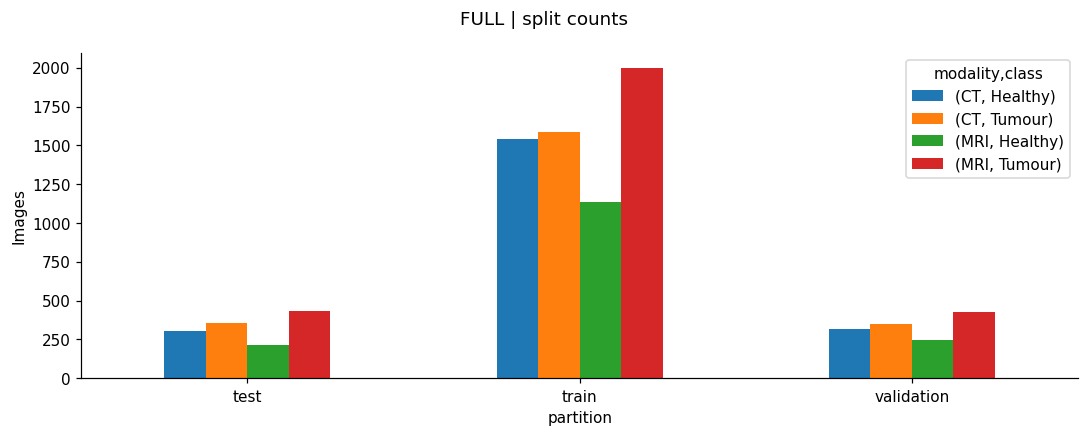

In [11]:
if clean.groupby('stratum').group.nunique().min() < 20:
    raise ValueError('Too few independent groups for the planned split.')
splitter = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
clean['partition'] = 'train'
for fold, (_, index) in enumerate(splitter.split(clean, clean.stratum, clean.group)):
    if fold < 3:
        clean.loc[index, 'partition'] = 'test'
    elif fold < 6:
        clean.loc[index, 'partition'] = 'validation'

def check_partitions(frame, column):
    assert frame.groupby('group')[column].nunique().max() == 1
    assert frame.groupby('pixel_hash')[column].nunique().max() == 1
    for _, subset in frame.groupby(column):
        assert set(subset.stratum) == {'CT_0', 'CT_1', 'MRI_0', 'MRI_1'}

check_partitions(clean, 'partition')
clean.to_csv(OUT / 'audit/splits.csv', index=False)
if MODE == 'smoke':
    active = clean.groupby(['partition', 'stratum'], group_keys=False).sample(
        n=SMOKE_PER_STRATUM, random_state=SEED).reset_index(drop=True)
else:
    active = clean.copy()
train = active[active.partition == 'train'].reset_index(drop=True)
validation = active[active.partition == 'validation'].reset_index(drop=True)
test = active[active.partition == 'test'].reset_index(drop=True)
development = active[active.partition != 'test'].reset_index(drop=True)
assert not set(development.group) & set(test.group)
fold_splitter = StratifiedGroupKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)
development['fold'] = -1
for fold, (_, index) in enumerate(fold_splitter.split(development, development.stratum, development.group)):
    development.loc[index, 'fold'] = fold
check_partitions(development, 'fold')
development.to_csv(OUT / 'audit/cv_splits.csv', index=False)
active.to_csv(OUT / 'audit/active_splits.csv', index=False)
counts = active.groupby(['partition', 'modality', 'class']).size().unstack(['modality', 'class'])
display(counts)
counts.plot.bar(figsize=(10, 4), rot=0, ylabel='Images')
save_figure('split_counts')

## Image preparation



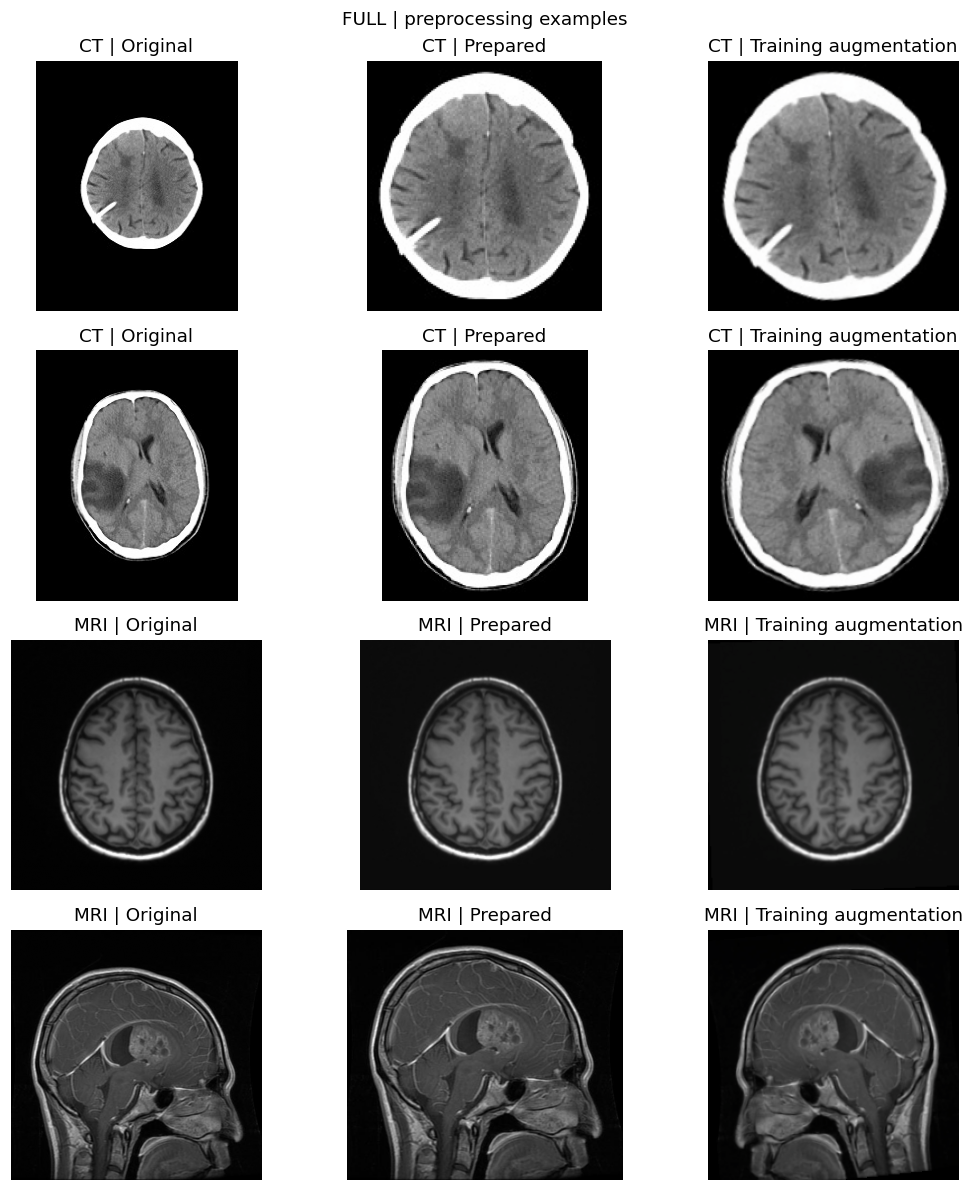

In [12]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

def prepare_image(image):
    image = ImageOps.exif_transpose(image).convert('L')
    if CROP_FOREGROUND:
        values = np.asarray(image)
        threshold = max(8, float(np.percentile(values, 95)) * .08)
        ys, xs = np.where(values > threshold)
        if len(xs):
            margin = max(2, int(.03 * max(image.size)))
            box = (max(0, int(xs.min()) - margin), max(0, int(ys.min()) - margin),
                   min(image.width, int(xs.max()) + margin + 1),
                   min(image.height, int(ys.max()) + margin + 1))
            if (box[2] - box[0]) * (box[3] - box[1]) >= .35 * image.width * image.height:
                image = image.crop(box)
    return image.convert('RGB')

def image_transform(training=False, augment=True):
    operations = [transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=InterpolationMode.BILINEAR)]
    if training and augment:
        operations += [transforms.RandomHorizontalFlip(), transforms.RandomRotation(
            10, interpolation=InterpolationMode.BILINEAR)]
    return transforms.Compose(operations + [transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class BrainImages(Dataset):
    def __init__(self, frame, training=False, augment=True):
        self.frame = frame.reset_index(drop=True)
        self.transform = image_transform(training, augment)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(ROOT / row.path) as source:
            image = self.transform(prepare_image(source))
        return image, torch.tensor(row.label, dtype=torch.float32), int(row.modality == 'MRI')

def loader(frame, training=False, augment=True, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(BrainImages(frame, training, augment), batch_size=BATCH_SIZE,
                      shuffle=training, num_workers=0, generator=generator,
                      pin_memory=DEVICE.type == 'cuda')

fig, axes = plt.subplots(4, 3, figsize=(10, 11))
for axis_row, (_, sample) in zip(axes, clean.groupby('stratum').first().iterrows()):
    with Image.open(ROOT / sample.path) as source:
        original = source.convert('L')
        prepared = prepare_image(source)
    augmented = image_transform(True)(prepared)
    augmented = (augmented.permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)
    for ax, value, title in zip(axis_row, [original, prepared, augmented],
                                ['Original', 'Prepared', 'Training augmentation']):
        ax.imshow(value, cmap='gray')
        ax.set_title(f'{sample.modality} | {title}')
        ax.axis('off')
save_figure('preprocessing_examples')
batch = next(iter(loader(train)))
assert batch[0].shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert torch.isfinite(batch[0]).all()